In [1]:
from google.colab import files

uploaded = files.upload()


Saving person2_submission_ff.zip to person2_submission_ff.zip


In [2]:
import zipfile
import io
import pandas as pd

zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    csv_path = (
        "person2_submission/data/processed/"
        "cybercrime_analysis_dataset.csv"
    )

    df = pd.read_csv(z.open(csv_path))

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nAvailable years:")
print(sorted(df["year"].unique()))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

Dataset loaded successfully!
Rows and columns: (216, 22)

Column names:
['state_ut_standard', 'year', 'reported_cases_raw', 'raw_value_text', 'reported_cases', 'case_value_status', 'quality_flag', 'population_persons', 'crime_rate_per_100k', 'previous_year_cases', 'previous_year_crime_rate_per_100k', 'absolute_change', 'annual_growth_pct', 'rolling_3yr_avg_cases', 'national_total_cases', 'national_share_pct', 'boundary_comparability', 'boundary_break_flag', 'source_id', 'source_url', 'table_page', 'source_file']

First 5 rows:


,state_ut_standard,year,reported_cases_raw,raw_value_text,reported_cases,case_value_status,quality_flag,population_persons,crime_rate_per_100k,previous_year_cases,...,annual_growth_pct,rolling_3yr_avg_cases,national_total_cases,national_share_pct,boundary_comparability,boundary_break_flag,source_id,source_url,table_page,source_file
0,Andaman and Nicobar Islands,2018,7.0,7.0,7.0,reported,NaN,67000,10.447761,NaN,...,NaN,NaN,27248.0,0.025690,current_boundary_series,False,S01,https://www.mha.gov.in/MHA1/Par2017/pdfs/par20...,Annexure-II 'State/UT-wise Cases Registered un...,S01_LS_USQ438_2025-12-02_AnnexII_2014-2023.txt
1,Andaman and Nicobar Islands,2019,2.0,2.0,2.0,reported,NaN,68000,2.941176,7.0,...,-71.428571,NaN,44735.0,0.004471,current_boundary_series,False,S01,https://www.mha.gov.in/MHA1/Par2017/pdfs/par20...,Annexure-II 'State/UT-wise Cases Registered un...,S01_LS_USQ438_2025-12-02_AnnexII_2014-2023.txt
2,Andaman and Nicobar Islands,2020,5.0,5.0,5.0,reported,NaN,68000,7.352941,2.0,...,150.000000,4.666667,50035.0,0.009993,current_boundary_series,False,S01,https://www.mha.gov.in/MHA1/Par2017/pdfs/par20...,Annexure-II 'State/UT-wise Cases Registered un...,S01_LS_USQ438_2025-12-02_AnnexII_2014-2023.txt
3,Andaman and Nicobar Islands,2021,8.0,8.0,8.0,reported,NaN,68000,11.764706,5.0,...,60.000000,5.000000,52974.0,0.015102,current_boundary_series,False,S01,https://www.mha.gov.in/MHA1/Par2017/pdfs/par20...,Annexure-II 'State/UT-wise Cases Registered un...,S01_LS_USQ438_2025-12-02_AnnexII_2014-2023.txt
4,Andaman and Nicobar Islands,2022,28.0,28.0,28.0,reported,NaN,69000,40.579710,8.0,...,250.000000,13.666667,65893.0,0.042493,current_boundary_series,False,S01,https://www.mha.gov.in/MHA1/Par2017/pdfs/par20...,Annexure-II 'State/UT-wise Cases Registered un...,S01_LS_USQ438_2025-12-02_AnnexII_2014-2023.txt



Available years:
[np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

Missing values:


,Missing values
state_ut_standard,0
year,0
reported_cases_raw,6
raw_value_text,6
reported_cases,2
case_value_status,0
quality_flag,212
population_persons,0
crime_rate_per_100k,4
previous_year_cases,39


,year,total_cases
0,2018,27248.0
1,2019,44735.0
2,2020,50035.0
3,2021,52974.0
4,2022,65893.0
5,2023,86420.0


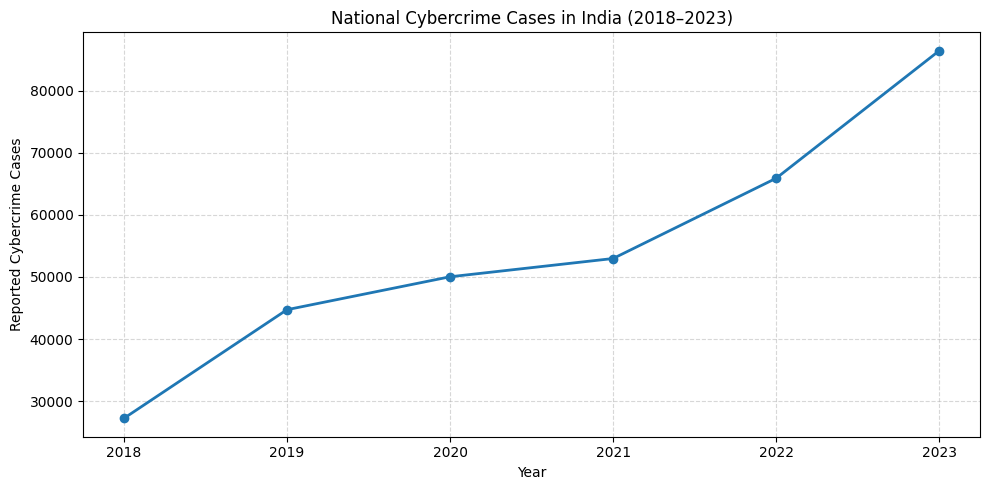

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare national totals: one value per year
national = (
    df.groupby("year")["national_total_cases"]
      .agg(["first", "nunique"])
      .reset_index()
)

# Check that the national total is consistent within each year
if (national["nunique"] > 1).any():
    raise ValueError("Different national totals found for the same year.")

national = national.rename(columns={"first": "total_cases"})
national = national.sort_values("year")

# Display the values used in the chart
display(national[["year", "total_cases"]])

# Create the line chart
plt.figure(figsize=(10, 5))
plt.plot(
    national["year"],
    national["total_cases"],
    marker="o",
    linewidth=2
)

plt.title("National Cybercrime Cases in India (2018–2023)")
plt.xlabel("Year")
plt.ylabel("Reported Cybercrime Cases")
plt.xticks(national["year"])
plt.grid(True, linestyle="--", alpha=0.5)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()

# Save the chart for your report
plt.savefig("01_national_cybercrime_trend.png", dpi=300)
plt.show()

In [4]:
from google.colab import files

files.download("01_national_cybercrime_trend.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Missing reported case counts: 0

Boundary comparability:
boundary_comparability
current_boundary_series    36
Name: count, dtype: int64


,state_ut_standard,reported_cases,boundary_comparability,boundary_break_flag
0,Andhra Pradesh,2341.0,current_boundary_series,False
1,Odisha,2348.0,current_boundary_series,False
2,Rajasthan,2435.0,current_boundary_series,False
3,Kerala,3295.0,current_boundary_series,False
4,Tamil Nadu,4121.0,current_boundary_series,False
5,Bihar,4450.0,current_boundary_series,False
6,Maharashtra,8103.0,current_boundary_series,False
7,Uttar Pradesh,10794.0,current_boundary_series,False
8,Telangana,18236.0,current_boundary_series,False
9,Karnataka,21889.0,current_boundary_series,False


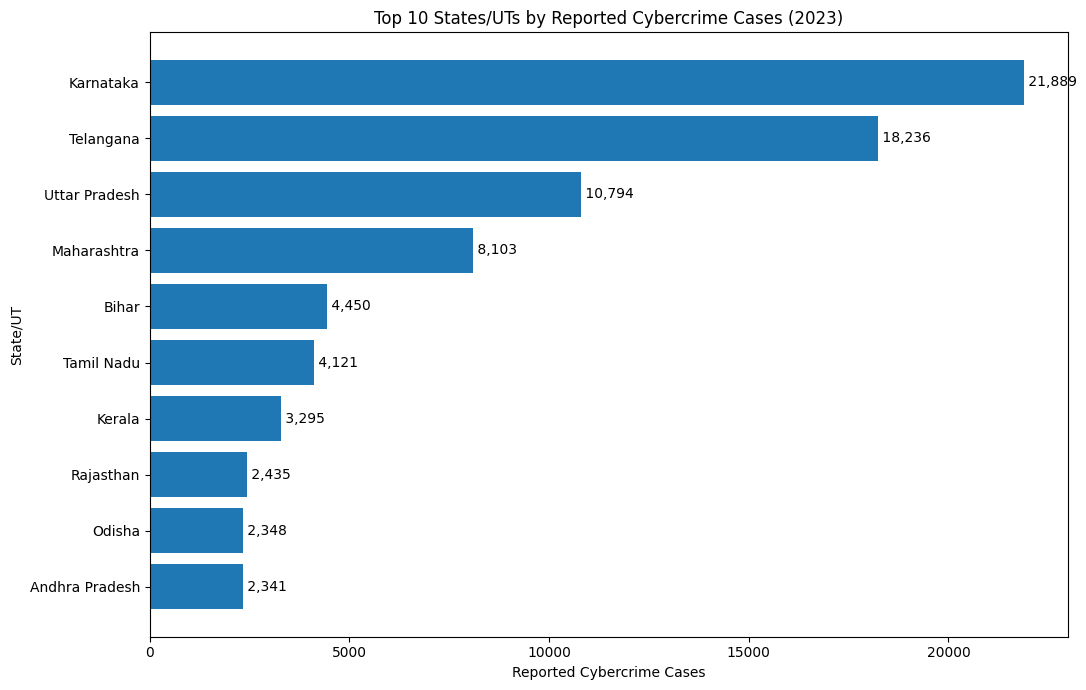

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Select the latest year
year_selected = 2023

data_2023 = df[df["year"] == year_selected].copy()

# Check missing case counts
print("Missing reported case counts:",
      data_2023["reported_cases"].isna().sum())

# Exclude rows where the case count is missing
data_2023 = data_2023.dropna(subset=["reported_cases"])

# Check boundary comparability
print("\nBoundary comparability:")
print(data_2023["boundary_comparability"].value_counts(dropna=False))

# Sort states by reported cases and select the top 10
top10 = (
    data_2023.sort_values("reported_cases", ascending=False)
             .head(10)
             .sort_values("reported_cases", ascending=True)
)

# Display the exact values used
display(
    top10[["state_ut_standard", "reported_cases",
           "boundary_comparability", "boundary_break_flag"]]
    .reset_index(drop=True)
)

# Create horizontal bar chart
plt.figure(figsize=(11, 7))

plt.barh(
    top10["state_ut_standard"],
    top10["reported_cases"]
)

plt.title("Top 10 States/UTs by Reported Cybercrime Cases (2023)")
plt.xlabel("Reported Cybercrime Cases")
plt.ylabel("State/UT")
plt.ticklabel_format(axis="x", style="plain")

# Add case counts beside bars
for i, value in enumerate(top10["reported_cases"]):
    plt.text(value, i, f" {value:,.0f}", va="center")

plt.tight_layout()
plt.savefig("02_top10_cybercrime_cases_2023.png", dpi=300)
plt.show()

In [6]:
from google.colab import files
files.download("02_top10_cybercrime_cases_2023.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,state_ut_standard,crime_rate_per_100k,boundary_comparability,boundary_break_flag
0,Uttar Pradesh,4.552855,current_boundary_series,False
1,Odisha,5.055333,current_boundary_series,False
2,Tamil Nadu,5.352435,current_boundary_series,False
3,Goa,5.446485,current_boundary_series,False
4,Maharashtra,6.382627,current_boundary_series,False
5,Kerala,9.188511,current_boundary_series,False
6,Karnataka,32.218608,current_boundary_series,False
7,Puducherry,36.476427,current_boundary_series,False
8,Telangana,47.761976,current_boundary_series,False
9,Andaman and Nicobar Islands,68.115942,current_boundary_series,False


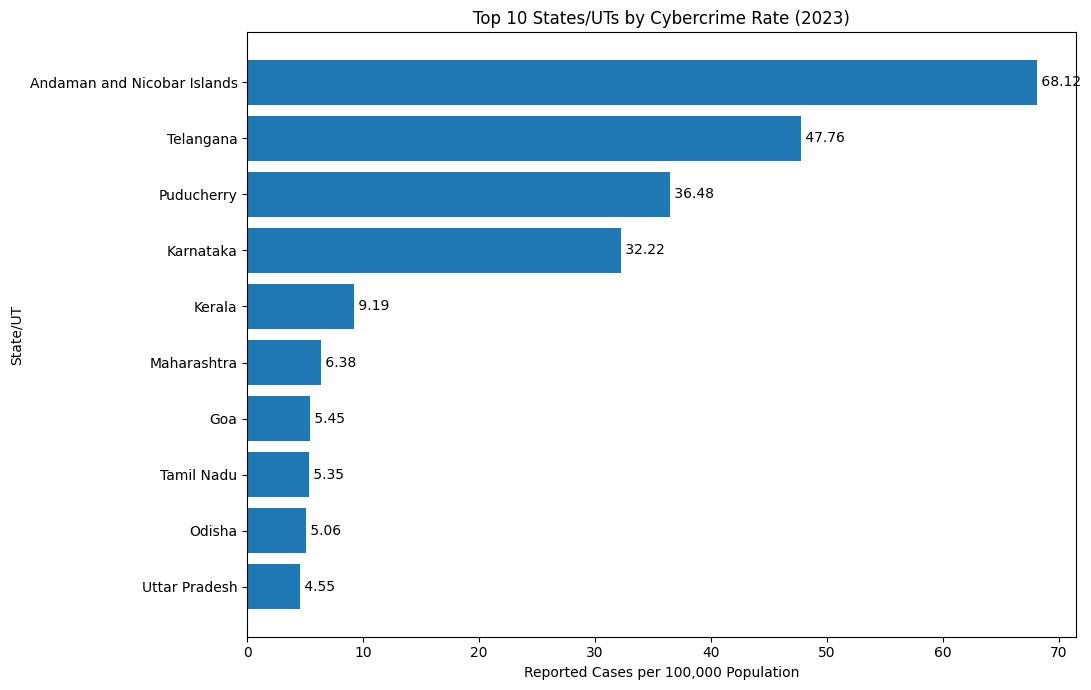

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Select 2023 data
data_2023 = df[df["year"] == 2023].copy()

# Exclude missing crime rates
data_2023 = data_2023.dropna(
    subset=["crime_rate_per_100k"]
)

# Sort by crime rate and select the top 10
top10_rate = (
    data_2023.sort_values(
        "crime_rate_per_100k",
        ascending=False
    )
    .head(10)
    .sort_values(
        "crime_rate_per_100k",
        ascending=True
    )
)

# Display the values used in the chart
display(
    top10_rate[
        ["state_ut_standard",
         "crime_rate_per_100k",
         "boundary_comparability",
         "boundary_break_flag"]
    ].reset_index(drop=True)
)

# Create the chart
plt.figure(figsize=(11, 7))

plt.barh(
    top10_rate["state_ut_standard"],
    top10_rate["crime_rate_per_100k"]
)

plt.title(
    "Top 10 States/UTs by Cybercrime Rate (2023)"
)
plt.xlabel("Reported Cases per 100,000 Population")
plt.ylabel("State/UT")

# Add value labels
for i, value in enumerate(
    top10_rate["crime_rate_per_100k"]
):
    plt.text(
        value, i, f" {value:.2f}",
        va="center"
    )

plt.tight_layout()
plt.savefig(
    "03_top10_cybercrime_rates_2023.png",
    dpi=300
)
plt.show()

In [8]:
from google.colab import files

plt.figure(3)
plt.savefig(
    "03_top10_cybercrime_rates_2023.png",
    dpi=300,
    bbox_inches="tight"
)

files.download("03_top10_cybercrime_rates_2023.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

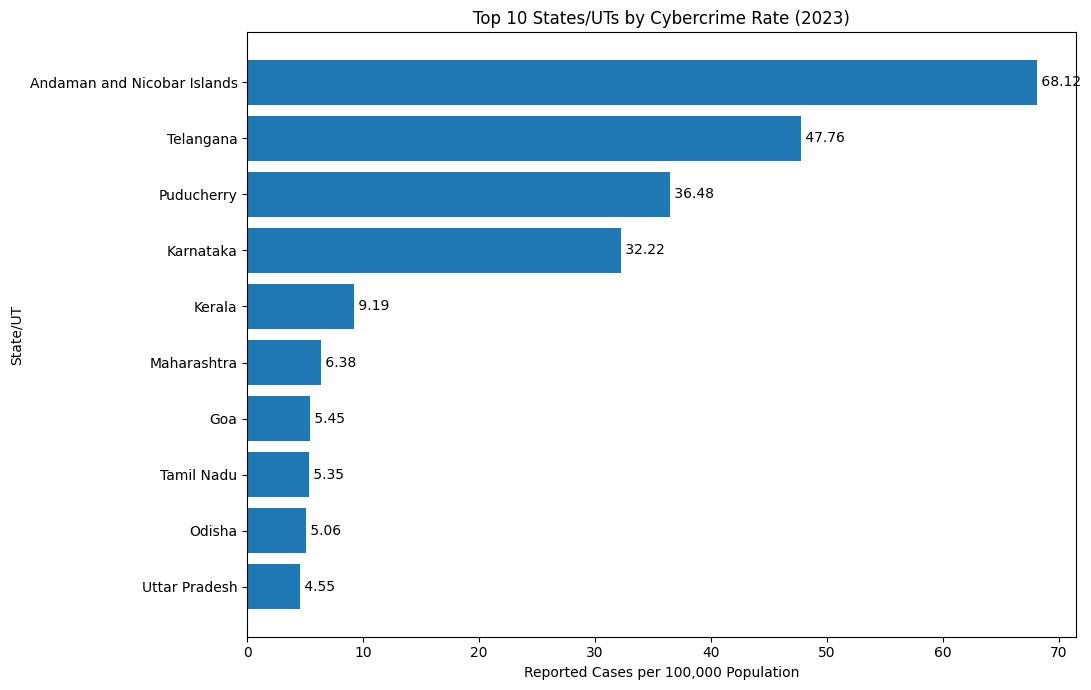

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Select 2023 data
data_2023 = df[df["year"] == 2023].copy()
data_2023 = data_2023.dropna(
    subset=["crime_rate_per_100k"]
)

# Select top 10 states by crime rate
top10_rate = (
    data_2023.sort_values(
        "crime_rate_per_100k",
        ascending=False
    )
    .head(10)
    .sort_values(
        "crime_rate_per_100k",
        ascending=True
    )
)

# Create a fresh chart
fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top10_rate["state_ut_standard"],
    top10_rate["crime_rate_per_100k"]
)

ax.set_title("Top 10 States/UTs by Cybercrime Rate (2023)")
ax.set_xlabel("Reported Cases per 100,000 Population")
ax.set_ylabel("State/UT")

for i, value in enumerate(top10_rate["crime_rate_per_100k"]):
    ax.text(value, i, f" {value:.2f}", va="center")

fig.tight_layout()

# Save this exact figure
fig.savefig(
    "03_top10_cybercrime_rates_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Download the saved chart
files.download("03_top10_cybercrime_rates_2023.png")

state_ut_standard,Bihar,Karnataka,Maharashtra,Tamil Nadu,Telangana,Uttar Pradesh
year,,,,,,
2018,374.0,5839.0,3511.0,295.0,1205.0,6280.0
2019,1050.0,12020.0,4967.0,385.0,2691.0,11416.0
2020,1512.0,10741.0,5496.0,782.0,5024.0,11097.0
2021,1413.0,8136.0,5562.0,1076.0,10303.0,8829.0
2022,1621.0,12556.0,8249.0,2082.0,15297.0,10117.0
2023,4450.0,21889.0,8103.0,4121.0,18236.0,10794.0


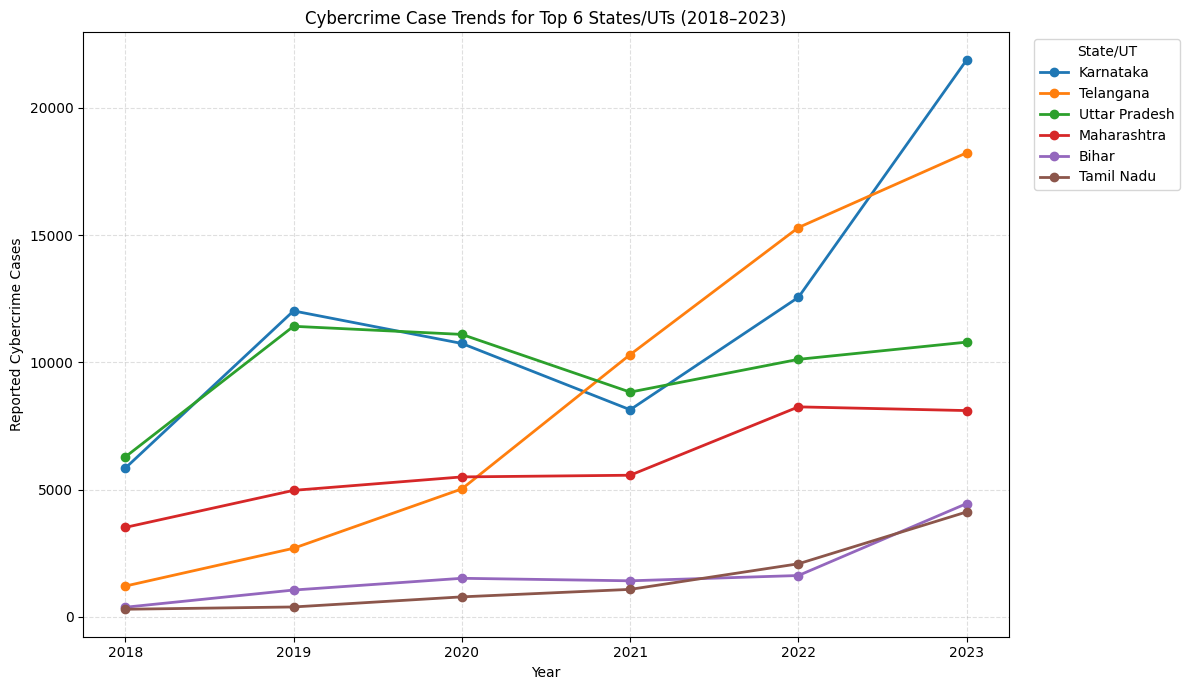

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Select the six states with the highest reported cases in 2023
data_2023 = df[df["year"] == 2023].dropna(
    subset=["reported_cases"]
)

top_states = (
    data_2023.sort_values(
        "reported_cases", ascending=False
    )
    .head(6)["state_ut_standard"]
    .tolist()
)

# Get these states' data across all available years
trend_data = df[
    df["state_ut_standard"].isin(top_states)
].copy()

# Display the data used
display(
    trend_data.pivot(
        index="year",
        columns="state_ut_standard",
        values="reported_cases"
    )
)

# Plot the trends
plt.figure(figsize=(12, 7))

for state in top_states:
    state_data = trend_data[
        trend_data["state_ut_standard"] == state
    ].sort_values("year")

    plt.plot(
        state_data["year"],
        state_data["reported_cases"],
        marker="o",
        linewidth=2,
        label=state
    )

plt.title(
    "Cybercrime Case Trends for Top 6 States/UTs (2018–2023)"
)
plt.xlabel("Year")
plt.ylabel("Reported Cybercrime Cases")
plt.xticks(sorted(df["year"].unique()))
plt.ticklabel_format(axis="y", style="plain")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="State/UT", bbox_to_anchor=(1.02, 1),
           loc="upper left")
plt.tight_layout()

plt.savefig(
    "04_statewise_trends_2018_2023.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [11]:
files.download("04_statewise_trends_2018_2023.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

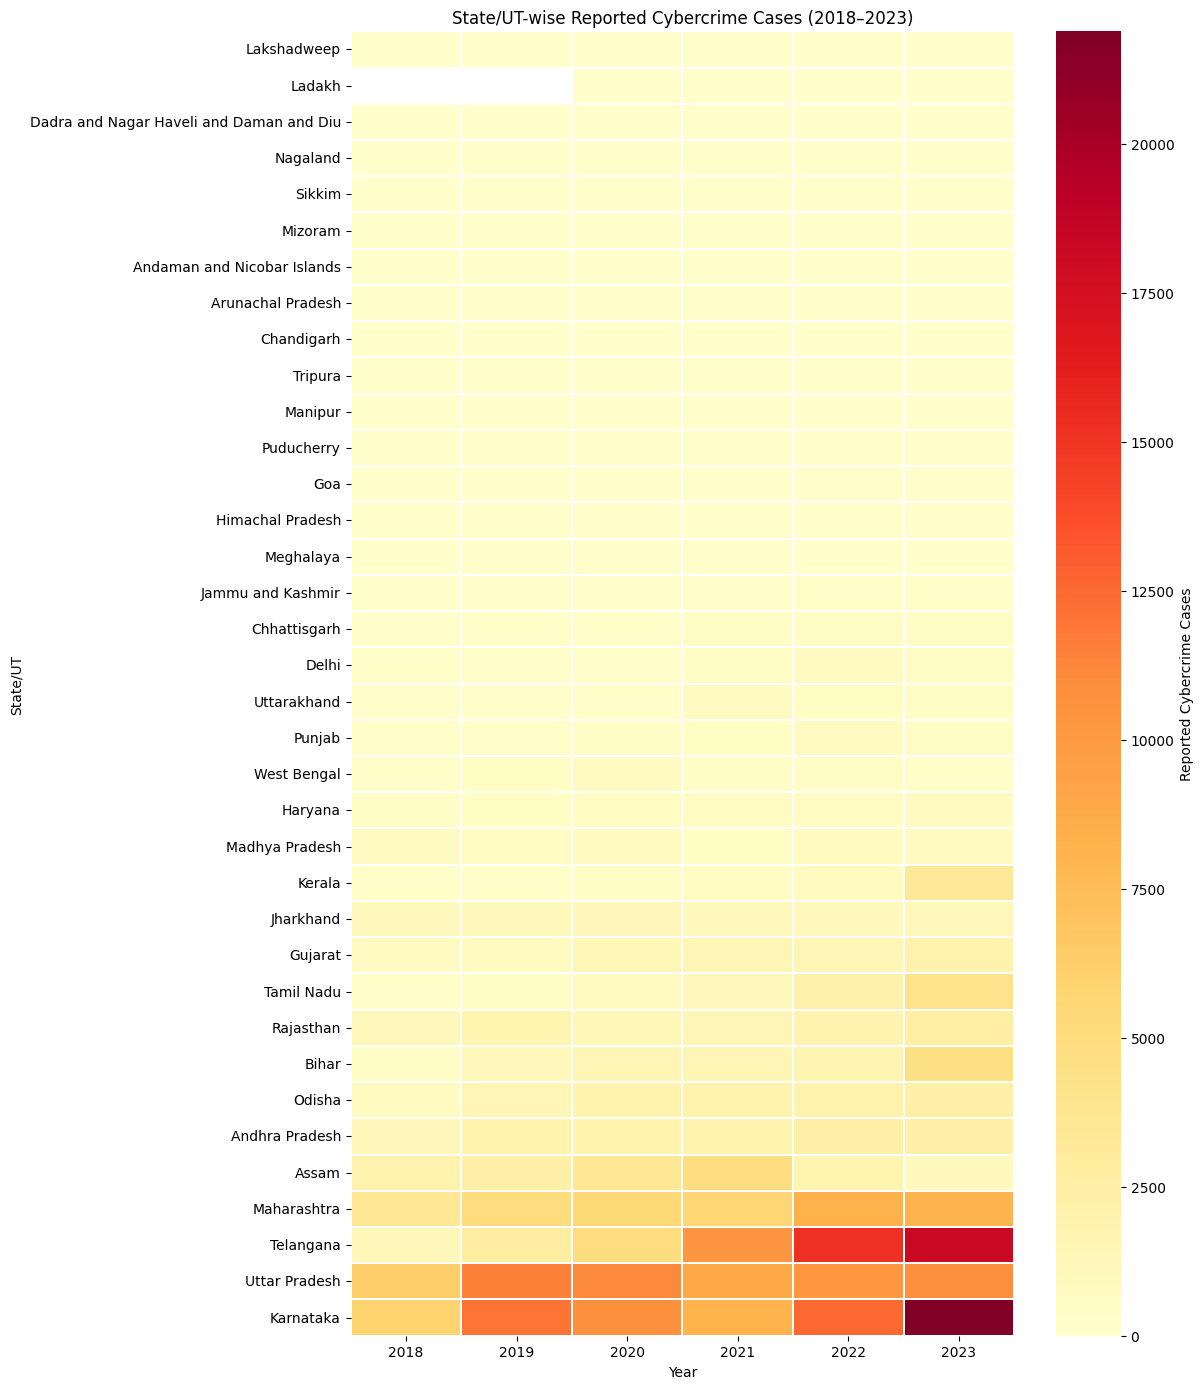

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Prepare state-year data
heatmap_data = df.pivot(
    index="state_ut_standard",
    columns="year",
    values="reported_cases"
)

# Sort states by their average reported cases
heatmap_data = heatmap_data.loc[
    heatmap_data.mean(axis=1).sort_values().index
]

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 14))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    linewidths=0.3,
    linecolor="white",
    mask=heatmap_data.isna(),
    cbar_kws={"label": "Reported Cybercrime Cases"},
    ax=ax
)

ax.set_title(
    "State/UT-wise Reported Cybercrime Cases (2018–2023)"
)
ax.set_xlabel("Year")
ax.set_ylabel("State/UT")

plt.tight_layout()

# Save chart
fig.savefig(
    "05_state_year_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Download chart
files.download("05_state_year_heatmap.png")

In [13]:
# Check the state/UT coverage for every year

coverage = df.pivot_table(
    index="state_ut_standard",
    columns="year",
    values="reported_cases",
    aggfunc="count"
)

print("Unique states/UTs:", df["state_ut_standard"].nunique())
print("\nNumber of non-missing case counts per year:")
print(coverage.notna().sum())

print("\nStates/UTs with missing case counts:")
display(coverage[coverage.isna().any(axis=1)])

print("\nStates/UTs with no reported case counts in any year:")
display(coverage[coverage.isna().all(axis=1)])

Unique states/UTs: 36

Number of non-missing case counts per year:
year
2018    36
2019    36
2020    36
2021    36
2022    36
2023    36
dtype: int64

States/UTs with missing case counts:


year,2018,2019,2020,2021,2022,2023
state_ut_standard,,,,,,



States/UTs with no reported case counts in any year:


year,2018,2019,2020,2021,2022,2023
state_ut_standard,,,,,,


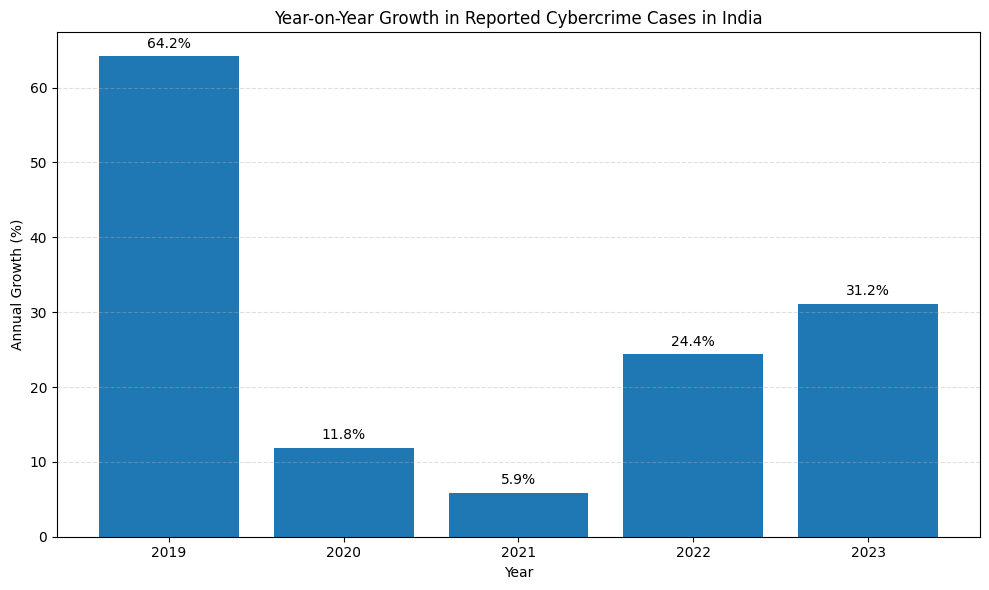